In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# 17 - Pay and productivity: long run, and how much does the deflator matter?
AMECO long series: nominal compensation per employee deflated by the GDP deflator (a 'producer' real wage), against output per employee and per hour. Then a robustness check of the 2005-2024 real-compensation result in notebook 05 across deflators.

,output/employee 1995-2024 (%),real comp 1995-2024 (%),output/hour 1995-2024 (%),wage share 1995,wage share 2024
ITA,-0.7,-5.6,6.1,53.8,51.1
DEU,16.4,14.8,33.3,59.9,59.1
FRA,20.4,22.2,26.0,57.1,57.9
ESP,12.0,4.8,18.3,59.8,55.9
GBR,31.6,41.1,38.1,52.4,56.2


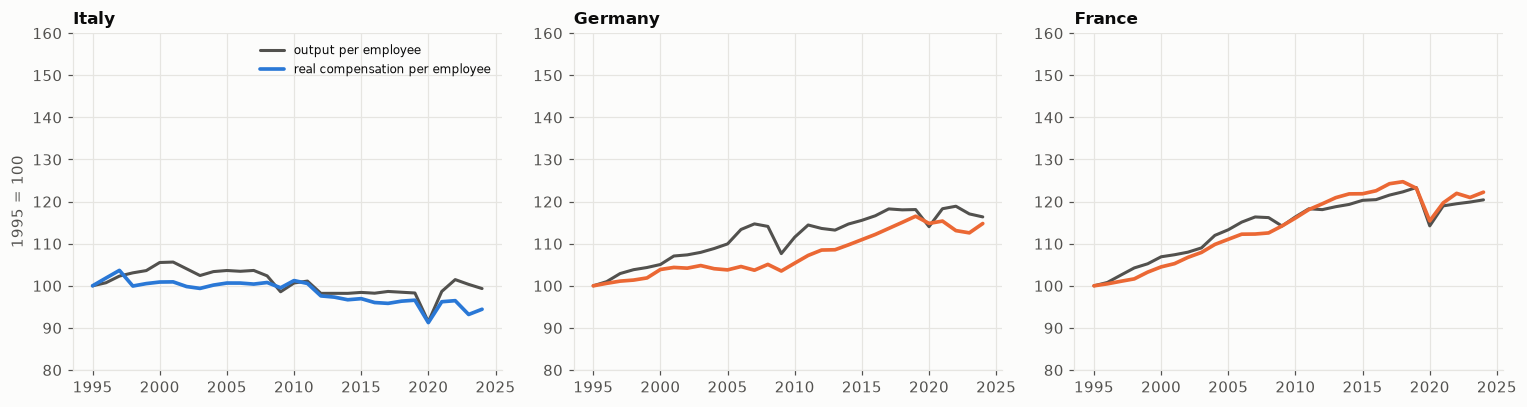

In [2]:
lh = load_long(); comp = long_wide(lh, "comp_per_employee_nominal_th"); defl = long_wide(lh, "gdp_deflator_2020_100"); gdp = long_wide(lh, "gdp_real_ncu_bn"); emp = long_wide(lh, "employment_th")
real_comp = comp / defl; prod_emp = gdp / emp; prod_hour = long_wide(lh, "gdp_real_per_hour_ncu")
def rebase95(w): return w / w.loc[1995] * 100
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, c in zip(axes, [ITALY, "DEU", "FRA"], strict=True):
    ax.plot(range(1995, 2025), rebase95(prod_emp).loc[1995:2024, c], color=INK2, lw=2, label="output per employee"); ax.plot(range(1995, 2025), rebase95(real_comp).loc[1995:2024, c], color=ITALY_C if c == ITALY else EU_C, lw=2.4, label="real compensation per employee")
    ax.set_title({"ITA": "Italy", "DEU": "Germany", "FRA": "France"}[c]); ax.set_ylim(80, 160)
axes[0].legend(fontsize=8); axes[0].set_ylabel("1995 = 100"); fig.tight_layout(); save(fig, "17_pay_vs_productivity")
rows = {}
for c in [ITALY, "DEU", "FRA", "ESP", "GBR"]:
    rows[c] = {"output/employee 1995-2024 (%)": (prod_emp.loc[2024, c] / prod_emp.loc[1995, c] - 1) * 100, "real comp 1995-2024 (%)": (real_comp.loc[2024, c] / real_comp.loc[1995, c] - 1) * 100,
               "output/hour 1995-2024 (%)": (prod_hour.loc[2024, c] / prod_hour.loc[1995, c] - 1) * 100, "wage share 1995": long_wide(lh, "wage_share_adjusted_pct_gdp").loc[1995, c], "wage share 2024": long_wide(lh, "wage_share_adjusted_pct_gdp").loc[2024, c]}
display(pd.DataFrame(rows).T.round(1))

Italy 2024 real compensation (2005 = 100): HICP deflator 90.5 | GDP deflator 93.8
Median of the other members: HICP 117.6 | GDP deflator 112.5 | Italy's rank among EU27 (1 = lowest): HICP 2, GDP deflator 3
rank correlation across countries: 0.88


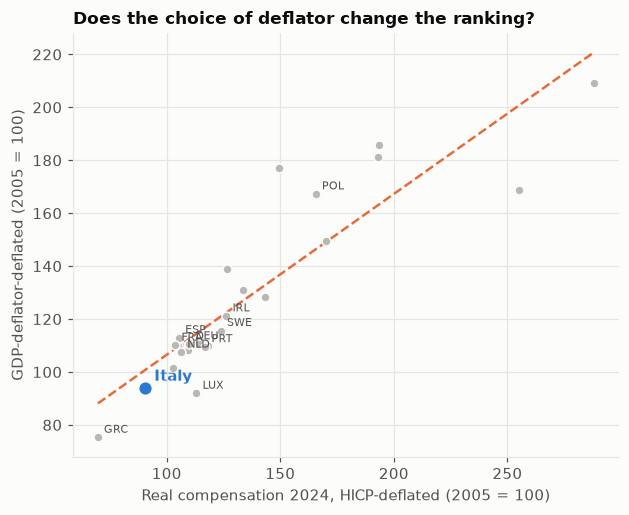

In [3]:
# Deflator robustness, 2005-2024: real compensation per employee (2005 = 100) with the HICP vs the GDP deflator
hicp = (1 + wide(panel, "hicp_inflation") / 100).cumprod(); hicp = hicp / hicp.loc[2005]
nom = comp.loc[2005:2024] / comp.loc[2005]
r_hicp = nom / hicp.loc[2005:2024].reindex(columns=nom.columns) * 100; r_gdp = nom / (defl.loc[2005:2024] / defl.loc[2005]) * 100
cmp_ = pd.DataFrame({"HICP": r_hicp.loc[2024], "GDP deflator": r_gdp.loc[2024]}).loc[[c for c in EU27_ISO3 if c in r_hicp.columns]].dropna()
print("Italy 2024 real compensation (2005 = 100): HICP deflator %.1f | GDP deflator %.1f" % (cmp_.loc[ITALY, "HICP"], cmp_.loc[ITALY, "GDP deflator"]))
print("Median of the other members: HICP %.1f | GDP deflator %.1f | Italy's rank among EU27 (1 = lowest): HICP %d, GDP deflator %d" % (cmp_.drop(ITALY).median()["HICP"], cmp_.drop(ITALY).median()["GDP deflator"], cmp_["HICP"].rank()[ITALY], cmp_["GDP deflator"].rank()[ITALY]))
fig, ax = plt.subplots(figsize=(6.4, 5)); scatter_italy(ax, cmp_["HICP"], cmp_["GDP deflator"], "Real compensation 2024, HICP-deflated (2005 = 100)", "GDP-deflator-deflated (2005 = 100)", "Does the choice of deflator change the ranking?"); save(fig, "17_deflator_scatter")
print("rank correlation across countries: %.2f" % cmp_.corr(method="spearman").iloc[0, 1])

corr: 0.85 | Italy productivity 0.03, real pay -0.29 (% per year); median others 1.01 / 0.79


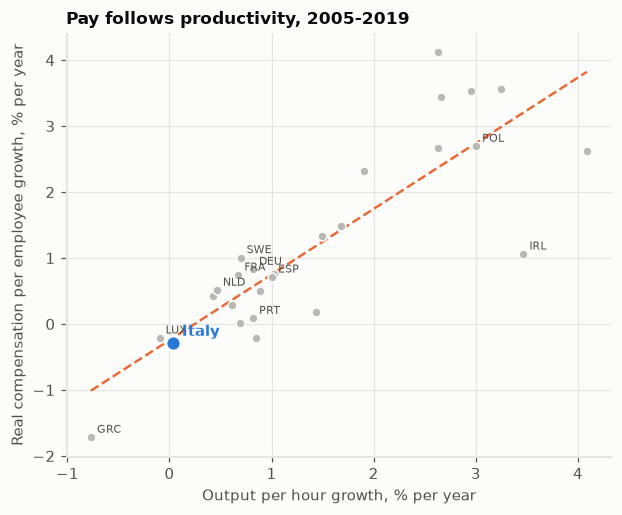

In [4]:
# Productivity growth and real pay growth across the EU27, 2005-2019 (average annual log growth, GDP-deflator real pay)
pg = (np.log(prod_hour.loc[2019] / prod_hour.loc[2005]) * 100 / 14); wg = (np.log(real_comp.loc[2019] / real_comp.loc[2005]) * 100 / 14)
fig, ax = plt.subplots(figsize=(6.4, 5)); scatter_italy(ax, pg.reindex(EU27_ISO3), wg.reindex(EU27_ISO3), "Output per hour growth, % per year", "Real compensation per employee growth, % per year", "Pay follows productivity, 2005-2019"); save(fig, "17_pay_productivity_scatter")
d = pd.concat([pg, wg], axis=1).reindex(EU27_ISO3).dropna(); print("corr:", round(d.iloc[:, 0].corr(d.iloc[:, 1]), 2), "| Italy productivity %.2f, real pay %.2f (%% per year); median others %.2f / %.2f" % (d.loc[ITALY].iloc[0], d.loc[ITALY].iloc[1], d.drop(ITALY).iloc[:, 0].median(), d.drop(ITALY).iloc[:, 1].median()))

## Takeaways (AMECO; 1995-2024 and 2005-2024)
- **Pay tracked a stagnant productivity.** Since 1995 Italian output per hour is up 6.1% (Germany 33.3%, France 26.0%, Spain 18.3%, UK 38.1%); output per employee is down 0.7% and real compensation per employee (GDP-deflated) is down 5.6%, against +14.8% in Germany, +22.2% in France, +4.8% in Spain and +41.1% in the UK. The adjusted wage share eased from 53.8% to 51.1% of GDP (Germany 59.9% to 59.1%).
- **The deflator changes the level, not the ranking.** For 2005-2024, Italian real compensation per employee is 90.5 (2005 = 100) with HICP and 93.8 with the GDP deflator, vs medians of 117.6 and 112.5 for the other members; Italy ranks 2nd or 3rd lowest in the EU27 with either, and the rankings correlate at 0.88. So the finding of a decline in real pay does not hinge on the deflator, though its size does (about -6% to -10%).
- **Pay follows productivity across countries** (correlation 0.85 for 2005-2019 growth rates): Italy sits at the bottom of both, with output per hour +0.03% a year (median 1.01%) and real pay -0.29% a year (median 0.79%).
- Caveat: compensation per employee is a total-economy average and includes composition effects (hours, part-time, sector mix); it is not the wage of a given job.